In [2]:
import pandas as pd
import re
import string

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import joblib

In [3]:
df = pd.read_csv("../data/processed/emails.csv")

df["subject"] = df["subject"].fillna("")
df["body"] = df["body"].fillna("")

df["text"] = df["subject"] + " " + df["body"]

print(df.head())

                                          subject  \
0                        Re: New Sequences Window   
1                       [zzzzteana] RE: Alexander   
2                       [zzzzteana] Moscow bomber   
3           [IRR] Klez: The Virus That  Won't Die   
4  Re: [zzzzteana] Nothing like mama used to make   

                                                body  label  \
0      Date:        Wed, 21 Aug 2002 10:54:46 -05...      0   
1  Martin A posted:\nTassos Papadopoulos, the Gre...      0   
2  Man Threatens Explosion In Moscow \n\nThursday...      0   
3  Klez: The Virus That Won't Die\n \nAlready the...      0   
4  >  in adding cream to spaghetti carbonara, whi...      0   

                                                text  
0  Re: New Sequences Window     Date:        Wed,...  
1  [zzzzteana] RE: Alexander Martin A posted:\nTa...  
2  [zzzzteana] Moscow bomber Man Threatens Explos...  
3  [IRR] Klez: The Virus That  Won't Die Klez: Th...  
4  Re: [zzzzteana] Nothing 

In [5]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Tokenize
    words = word_tokenize(text)

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word.isalpha() and word not in stop_words
    ]

    return " ".join(words)

In [6]:
df["clean_text"] = df["text"].apply(preprocess)

df[["text", "clean_text"]].head()

,text,clean_text
0,"Re: New Sequences Window Date: Wed,...",new sequence window date wed aug chris garrigu...
1,[zzzzteana] RE: Alexander Martin A posted:\nTa...,zzzzteana alexander martin posted tasso papado...
2,[zzzzteana] Moscow bomber Man Threatens Explos...,zzzzteana moscow bomber man threatens explosio...
3,[IRR] Klez: The Virus That Won't Die Klez: Th...,irr klez virus wont die klez virus wont die al...
4,Re: [zzzzteana] Nothing like mama used to make...,zzzzteana nothing like mama used make adding c...


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["clean_text"])

y = df["label"]

print(X.shape)
print(y.shape)

(5996, 5000)
(5996,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(4796, 5000)
(1200, 5000)


In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("✅ Random Forest trained successfully!")

✅ Random Forest trained successfully!


In [10]:
rf_predictions = rf_model.predict(X_test)

print("Prediction completed!")

Prediction completed!


In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, rf_predictions))

print("\nClassification Report\n")
print(classification_report(y_test, rf_predictions))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, rf_predictions))

Accuracy: 0.9983333333333333

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1001
           1       0.99      1.00      0.99       199

    accuracy                           1.00      1200
   macro avg       1.00      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200


Confusion Matrix

[[999   2]
 [  0 199]]


In [12]:
import joblib

joblib.dump(rf_model, "../models/random_forest.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


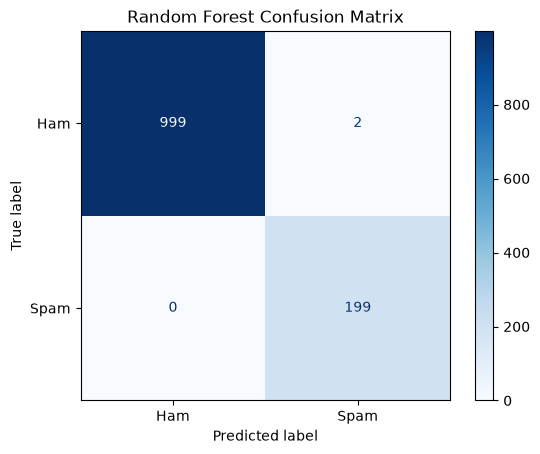

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")

plt.savefig("../reports/random_forest_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight")

plt.show()